In [1]:
# ===============================
# Imports & configuration
# ===============================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from pypfopt import (
    EfficientFrontier,
    risk_models,
    expected_returns,
    HRPOpt,
)

import matplotlib.pyplot as plt
from adjustText import adjust_text

from arch import arch_model

from utils import (
    port_data_load_prices_bbg,      
    port_data_compute_returns,
    port_data_load_benchmark_bbg,  
    port_metrics_expected_annual_return,
    port_metrics_volatility_annual,
    port_metrics_sharpe_ratio,
    port_metrics_sortino_ratio,
    port_metrics_drawdown_max,
    port_metrics_tracking_error,
    port_metrics_information_ratio,
    port_utils_clean_weights,
    port_data_summary_assets,
)

In [2]:
# -------------------------------
# User-adjustable parameters
# -------------------------------

"""
Backtest windows and outputs
----------------------------

In-sample (IS):
    2016-10-01 to 2021-09-30 (exactly 5 years of historical data).

Out-of-sample (OOS):
    2021-10-01 to 2025-09-30 (≈ 4 years of monthly rebalanced testing).
    Models are re-estimated monthly on rolling 5-year windows.

First OOS month:
    October 2021 (weights computed at 2021-09-30).

Last OOS month:
    September 2025 (data ends 2025-10-01, so October 2025 not evaluated).

Live next-month weights:
    Fit on data from 2020-10-01 to 2025-09-30 (latest 5-year window),
    representing portfolio allocations for October 2025.
"""

start_date_text = "2016-10-01"   # start of in-sample
split_date_text = "2021-09-30"   # end of in-sample
end_date_text   = "2025-10-01"   # end of out-of-sample

# All available Bloomberg assets # <----- MODIFY AS NEEDED!
assets_list = [
    "SMH",   # VanEck Vectors Semiconductor ETF
    "USMV",  # iShares MSCI USA Min Vol Factor ETF
    "GDX",   # VanEck Gold Miners ETF
    "VB",    # Vanguard Small-Cap ETF
    "QQQ",   # Invesco QQQ Trust
    "TAN",   # Invesco Solar ETF
    "IVV",   # iShares Core S&P 500 ETF
    "XLF",   # Financial Select Sector SPDR Fund
    "NBCM",  # Nuveen Nasdaq 100 Dynamic Overwrite Fund
    "VYM",   # Vanguard High Dividend Yield ETF
    "GLD",   # SPDR Gold Shares
    "XLV",   # Health Care Select Sector SPDR Fund
    "VOO",   # Vanguard S&P 500 ETF
    "AIVC",  # Amplify International Online Retail ETF
    "XLK",   # Technology Select Sector SPDR Fund
    "SPY",   # SPDR S&P 500 ETF Trust
    "IGSB",  # iShares Short-Term Corporate Bond ETF
    "IEFA",  # iShares MSCI EAFE ETF
    "EQQQ",  # Invesco EQQQ NASDAQ-100 UCITS ETF
    "IEMG",  # iShares Core MSCI Emerging Markets ETF
]

benchmark_csv_path      = "benchmark.csv"  # located in bloomberg_data/
risk_free_rate_annual   = 0.035
trading_days_per_year   = 252
rolling_window_days     = 252 * 5   # 5 years of daily data
rebalance_frequency_str = "M"       # monthly

In [3]:
# ===========================================
# Load Data (Daily)
# ===========================================

prices_frame = port_data_load_prices_bbg(assets_list, start_date_text, end_date_text)
returns_frame = port_data_compute_returns(prices_frame)

# Load benchmark (same Bloomberg format)
benchmark_return_series = port_data_load_benchmark_bbg(
    data_directory="bloomberg_data",
    file_name=benchmark_csv_path,
    start_date_text=start_date_text,
    end_date_text=end_date_text,
)

# Align all data to common calendar
common_index = returns_frame.index.intersection(benchmark_return_series.index)
prices_frame  = prices_frame.loc[common_index]
returns_frame = returns_frame.loc[common_index]
benchmark_return_series = benchmark_return_series.loc[common_index]


--- Bloomberg Price Data Loading ---
[INFO] Date range: 2016-10-03 → 2025-10-01
[WARN] Remaining NaNs detected after alignment (forward-filled):
       EQQQ: 1 NaNs | first: ['2016-10-03'] | last: ['2016-10-03']
[INFO] Loaded tickers: ['SMH', 'USMV', 'GDX', 'VB', 'QQQ', 'TAN', 'IVV', 'XLF', 'NBCM', 'VYM', 'GLD', 'XLV', 'VOO', 'AIVC', 'XLK', 'SPY', 'IGSB', 'IEFA', 'EQQQ', 'IEMG']
[INFO] Missing values handled using forward fill.
--- End Bloomberg Price Data Loading ---


--- Bloomberg Benchmark Loading ---
[INFO] No NaNs detected. Data fully continuous.
[INFO] Date range: 2016-10-04 → 2025-10-01
[INFO] Missing values handled using forward fill.
--- End Bloomberg Benchmark Loading ---



In [4]:
# ===============================
# Asset Diagnostics
# ===============================

asset_summary = port_data_summary_assets(
    returns_frame,
    benchmark_return_series=benchmark_return_series,
    risk_free_rate_annual=risk_free_rate_annual,
    trading_days_per_year=trading_days_per_year,
    split_date_text=split_date_text,     
)


[INFO] Using in-sample period up to 2021-09-30 for analysis.

--- Asset Annualized Performance Summary ---
[INFO] Analysis period: 2016-10-05 → 2021-09-30

           Mean (Ann.)  Vol (Ann.)  Sharpe (Ann.)  Sortino (Ann.)  TE (Ann.)  \
SMH           0.311537    0.295624       0.935434        1.479830   0.231974   
USMV          0.128435    0.161217       0.579562        0.852783   0.087599   
GDX           0.115840    0.363357       0.222480        0.359229   0.352293   
VB            0.153366    0.218182       0.542510        0.805275   0.142304   
QQQ           0.246366    0.218811       0.965973        1.472519   0.148264   
TAN           0.345505    0.360829       0.860531        1.394721   0.310129   
IVV           0.170931    0.188588       0.720782        1.065023   0.106644   
XLF           0.182358    0.249879       0.589717        0.914625   0.184613   
NBCM          0.068636    0.134709       0.249691        0.369193   0.120089   
VYM           0.119858    0.182134       0.

In [5]:
# ===========================================
# Model Definitions 
# ===========================================

"""LW for markowitz and minvar; 2 to 15% for markowitz and minvar; HRP standardized to avoid exteme weights."""

def lw_covariance(prices_window: pd.DataFrame) -> pd.DataFrame:
    return risk_models.CovarianceShrinkage(prices_window).ledoit_wolf()


def model_markowitz_constrained(window_prices: pd.DataFrame) -> pd.Series:
    mu  = expected_returns.mean_historical_return(window_prices)
    cov = lw_covariance(window_prices)
    ef = EfficientFrontier(mu, cov, weight_bounds=(0.02, 0.15))
    ef.max_sharpe(risk_free_rate=risk_free_rate_annual)
    return port_utils_clean_weights(ef.clean_weights())


def model_minvar_constrained(window_prices: pd.DataFrame) -> pd.Series:
    mu  = expected_returns.mean_historical_return(window_prices)
    cov = lw_covariance(window_prices)
    ef = EfficientFrontier(mu, cov, weight_bounds=(0.02, 0.15))
    ef.min_volatility()
    return port_utils_clean_weights(ef.clean_weights())


def model_hrp(window_returns: pd.DataFrame) -> pd.Series:
    stds = window_returns.std(ddof=0).replace(0.0, np.nan)
    standardized = window_returns.divide(stds)
    model = HRPOpt(standardized.dropna(axis=1, how="any"))
    w = model.optimize()
    return port_utils_clean_weights(w)


def model_equal(window_prices: pd.DataFrame) -> pd.Series:
    cols = window_prices.columns
    return pd.Series(1.0 / len(cols), index=cols)

In [6]:
# ===========================================
# Rolling OOS Backtest (Daily estimation, Monthly rebalance)
# ===========================================

def port_backtest_rolling_all_models_daily(
    prices_daily: pd.DataFrame,
    returns_daily: pd.DataFrame,
    benchmark_daily: pd.Series,
    start_oos: str,
    window_days: int = 252*5,
    risk_free_annual: float = 0.0,
    trading_days_per_year: int = 252,
):
    """Daily-estimation, monthly-rebalance backtest."""
    rebalance_dates = returns_daily.resample("M").last().index
    rebalance_dates = rebalance_dates[rebalance_dates >= pd.Timestamp(start_oos)]

    model_funcs = {
        "markowitz_constrained": ("prices",  model_markowitz_constrained),
        "minimum_variance_constrained":      ("prices",  model_minvar_constrained),
        "risk_parity_hrp":       ("returns", model_hrp),
        "equal_weighted":        ("prices",  model_equal),
    }

    portfolios_oos_daily = {n: [] for n in model_funcs}
    weights_history = {n: [] for n in model_funcs}

    for date in rebalance_dates:
        window_end = date
        window_start = date - pd.Timedelta(days=window_days)
        win_prices  = prices_daily.loc[(prices_daily.index >= window_start) & (prices_daily.index <= window_end)]
        win_returns = returns_daily.loc[(returns_daily.index >= window_start) & (returns_daily.index <= window_end)]
        if len(win_prices) < 100 or len(win_returns) < 100:
            continue

        next_month_start = date + pd.offsets.Day(1)
        next_month_end   = date + pd.offsets.MonthEnd(1)
        next_returns = returns_daily.loc[(returns_daily.index >= next_month_start) & (returns_daily.index <= next_month_end)]
        if next_returns.empty:
            continue

        for name, (mode, func) in model_funcs.items():
            try:
                w = func(win_prices if mode=="prices" else win_returns)
                w = w.reindex(next_returns.columns).fillna(0.0)
                port_daily = (next_returns[w.index] * w).sum(axis=1)
                portfolios_oos_daily[name].append(port_daily)
                weights_history[name].append(pd.Series(w, name=next_month_end))
            except Exception:
                continue

    for name in portfolios_oos_daily:
        if portfolios_oos_daily[name]:
            portfolios_oos_daily[name] = pd.concat(portfolios_oos_daily[name]).sort_index()
        else:
            portfolios_oos_daily[name] = pd.Series(dtype=float)
    for name in weights_history:
        if weights_history[name]:
            weights_history[name] = pd.DataFrame(weights_history[name]).sort_index()
        else:
            weights_history[name] = pd.DataFrame()

    rows, idx = [], []
    for name, s in portfolios_oos_daily.items():
        common = s.index.intersection(benchmark_daily.index)
        s, b = s.loc[common], benchmark_daily.loc[common]
        if len(s) < 5: 
            continue
        rows.append({
            "Return (Ann.)":  port_metrics_expected_annual_return(s, trading_days_per_year),
            "Vol (Ann.)":     port_metrics_volatility_annual(s, trading_days_per_year),
            "Max DD":         port_metrics_drawdown_max(s),
            "Sharpe (Ann.)":  port_metrics_sharpe_ratio(s, risk_free_annual, trading_days_per_year),
            "Sortino (Ann.)": port_metrics_sortino_ratio(s, risk_free_annual, trading_days_per_year),
            "TE (Ann.)":      port_metrics_tracking_error(s, b, trading_days_per_year),
            "Info (Ann.)":    port_metrics_information_ratio(s, b, trading_days_per_year),
        })
        idx.append(name)
    metrics_table = pd.DataFrame(rows, index=idx)

    # live next-month weights (fit on most recent window)
    win_prices_final  = prices_daily.iloc[-window_days:]
    win_returns_final = returns_daily.iloc[-window_days:]
    live_next_weights = {}
    for name, (mode, func) in model_funcs.items():
        try:
            w = func(win_prices_final if mode=="prices" else win_returns_final)
            live_next_weights[name] = w.reindex(prices_daily.columns).fillna(0.0)
        except Exception:
            live_next_weights[name] = pd.Series(dtype=float)

    return portfolios_oos_daily, weights_history, metrics_table, live_next_weights

In [7]:
# ===========================================
# Run Backtest
# ===========================================

portfolios_oos_daily, weights_history_oos, metrics_table_oos, live_next_weights = port_backtest_rolling_all_models_daily(
    prices_daily=prices_frame,
    returns_daily=returns_frame,
    benchmark_daily=benchmark_return_series,
    start_oos="2021-09-30",
    window_days=rolling_window_days,
    risk_free_annual=risk_free_rate_annual,
    trading_days_per_year=trading_days_per_year,
)

In [8]:
# ===========================================
# Present Results
# ===========================================

print("\n" + "="*90)
print("=== OUT-OF-SAMPLE PERFORMANCE METRICS (Full 2021–2025, Daily estimation, Monthly rebalance) ===")
print("="*90)
print(metrics_table_oos.round(4))

# ===== Year-by-Year breakdown =====
print("\n" + "="*90)
print("=== YEAR-BY-YEAR OOS METRICS (2022–2025) ===")
print("="*90)
years = sorted(set(portfolios_oos_daily["equal_weighted"].index.year))
for year in years:
    rows, idx = [], []
    for name, s in portfolios_oos_daily.items():
        s_year = s[s.index.year == year]
        b_year = benchmark_return_series[benchmark_return_series.index.year == year]
        common = s_year.index.intersection(b_year.index)
        s_year, b_year = s_year.loc[common], b_year.loc[common]
        if len(s_year) < 10:
            continue
        rows.append({
            "Return (Ann.)":  port_metrics_expected_annual_return(s_year, trading_days_per_year),
            "Vol (Ann.)":     port_metrics_volatility_annual(s_year, trading_days_per_year),
            "Max DD":         port_metrics_drawdown_max(s_year),
            "Sharpe (Ann.)":  port_metrics_sharpe_ratio(s_year, risk_free_rate_annual, trading_days_per_year),
            "Sortino (Ann.)": port_metrics_sortino_ratio(s_year, risk_free_rate_annual, trading_days_per_year),
            "TE (Ann.)":      port_metrics_tracking_error(s_year, b_year, trading_days_per_year),
            "Info (Ann.)":    port_metrics_information_ratio(s_year, b_year, trading_days_per_year),
        })
        idx.append(name)
    metrics_year = pd.DataFrame(rows, index=idx)
    print(f"\n--- YEAR {year} ---")
    print(metrics_year.round(4))

# ===== Live weights for next month =====
print("\n" + "="*90)
print("=== LIVE NEXT-MONTH WEIGHTS (Fit on Most Recent 5 Years) ===")
print("="*90)
for name, w in live_next_weights.items():
    if not w.empty:
        print(f"\n--- {name} ---")
        print(w.sort_values(ascending=False).round(4))

print("\nDone.")


=== OUT-OF-SAMPLE PERFORMANCE METRICS (Full 2021–2025, Daily estimation, Monthly rebalance) ===
                              Return (Ann.)  Vol (Ann.)  Max DD  \
markowitz_constrained                0.1253      0.1505 -0.2195   
minimum_variance_constrained         0.1101      0.1036 -0.1522   
risk_parity_hrp                      0.1145      0.1397 -0.2165   
equal_weighted                       0.1241      0.1541 -0.2305   

                              Sharpe (Ann.)  Sortino (Ann.)  TE (Ann.)  \
markowitz_constrained                0.5998          0.9793     0.0818   
minimum_variance_constrained         0.7249          1.1769     0.0489   
risk_parity_hrp                      0.5696          0.9365     0.0613   
equal_weighted                       0.5782          0.9545     0.0704   

                              Info (Ann.)  
markowitz_constrained              0.7453  
minimum_variance_constrained       0.9375  
risk_parity_hrp                    0.8203  
equal_weighted      

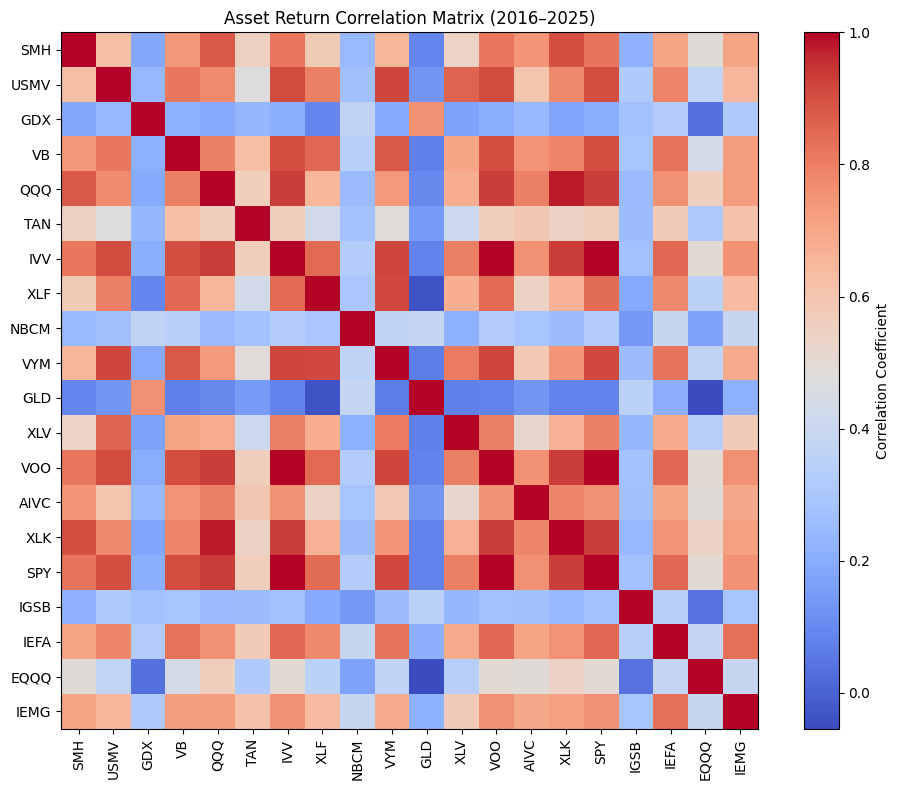


=== Correlation Summary ===
Average pairwise correlation: 0.534
Highest correlation pair: ('IVV', 'VOO') = 1.000
Lowest correlation pair: ('GLD', 'EQQQ') = -0.054


In [9]:
# ==================================================
# Asset Correlation Matrix (Full Period)
# ==================================================

corr_frame = returns_frame.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_frame, cmap="coolwarm", interpolation="nearest")
plt.colorbar(label="Correlation Coefficient")
plt.xticks(ticks=np.arange(len(corr_frame.columns)), labels=corr_frame.columns, rotation=90)
plt.yticks(ticks=np.arange(len(corr_frame.columns)), labels=corr_frame.columns)
plt.title("Asset Return Correlation Matrix (2016–2025)")
plt.tight_layout()
plt.show()

# Summary statistics (excluding self-correlations)
corr_values = corr_frame.where(~np.eye(len(corr_frame), dtype=bool))
corr_stack = corr_values.stack()
avg_corr = corr_stack.mean()
max_pair = corr_stack.idxmax()
min_pair = corr_stack.idxmin()

print("\n=== Correlation Summary ===")
print(f"Average pairwise correlation: {avg_corr:.3f}")
print(f"Highest correlation pair: {max_pair} = {corr_stack[max_pair]:.3f}")
print(f"Lowest correlation pair: {min_pair} = {corr_stack[min_pair]:.3f}")

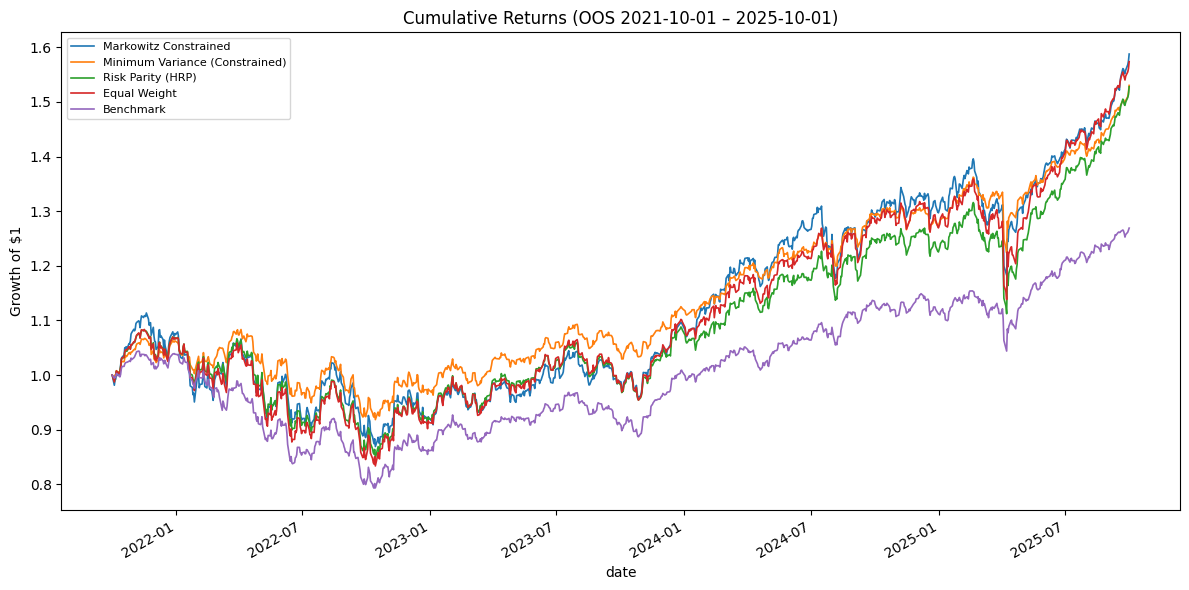

In [10]:
# ==================================================
# Cumulative Returns (Wealth) Plot  
# ==================================================

# --- Unified order & display names ---
ordered_models = [
    "markowitz_constrained",
    "minimum_variance_constrained",
    "risk_parity_hrp",
    "equal_weighted"
]
pretty_names = {
    "markowitz_constrained": "Markowitz Constrained",
    "minimum_variance_constrained": "Minimum Variance (Constrained)",
    "risk_parity_hrp": "Risk Parity (HRP)",
    "equal_weighted": "Equal Weight"
}

plt.figure(figsize=(12,6))

# 1) keep only models that actually have OOS data
available_models = [m for m in ordered_models if not portfolios_oos_daily[m].empty]

# 2) find common OOS index across all selected models AND the benchmark
common_idx = benchmark_return_series.index
for m in available_models:
    common_idx = common_idx.intersection(portfolios_oos_daily[m].index)
common_idx = common_idx.sort_values()
if len(common_idx) == 0:
    raise ValueError("No common dates across selected models and benchmark for OOS wealth plotting.")

# 3) slice to common index
series_dict = {
    pretty_names[m]: portfolios_oos_daily[m].loc[common_idx]
    for m in available_models
}
series_dict["Benchmark"] = benchmark_return_series.loc[common_idx]

# 4) build wealth and rebase to 1 at the common start
wealth = pd.DataFrame({k: (1 + v).cumprod() for k, v in series_dict.items()})
wealth = wealth / wealth.iloc[0]  # explicit rebase (ensures exact 1.0 at start)

wealth.plot(ax=plt.gca(), lw=1.2)
start_lbl = common_idx.min().date()
end_lbl   = common_idx.max().date()
plt.title(f"Cumulative Returns (OOS {start_lbl} – {end_lbl})", fontsize=12)
plt.ylabel("Growth of $1")
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

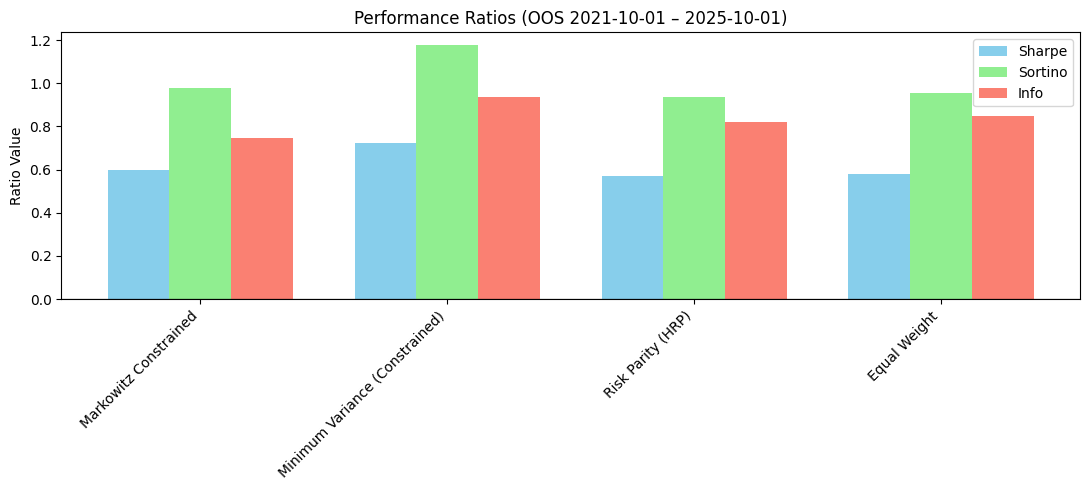

In [11]:
# ==================================================
# Ratios Comparison (Full-period)
# ==================================================

plot_metrics = metrics_table_oos.loc[ordered_models, ["Sharpe (Ann.)", "Sortino (Ann.)", "Info (Ann.)"]]

plt.figure(figsize=(11,5))
bar_width = 0.25
x = np.arange(len(plot_metrics.index))
plt.bar(x - bar_width, plot_metrics["Sharpe (Ann.)"],  width=bar_width, label="Sharpe",  color="skyblue")
plt.bar(x,             plot_metrics["Sortino (Ann.)"], width=bar_width, label="Sortino", color="lightgreen")
plt.bar(x + bar_width, plot_metrics["Info (Ann.)"],    width=bar_width, label="Info",    color="salmon")
plt.axhline(0, color="black", lw=1, alpha=0.4)
plt.title(f"Performance Ratios (OOS {start_lbl} – {end_lbl})", fontsize=12)
plt.ylabel("Ratio Value")
plt.xticks(x, [pretty_names[m] for m in ordered_models], rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

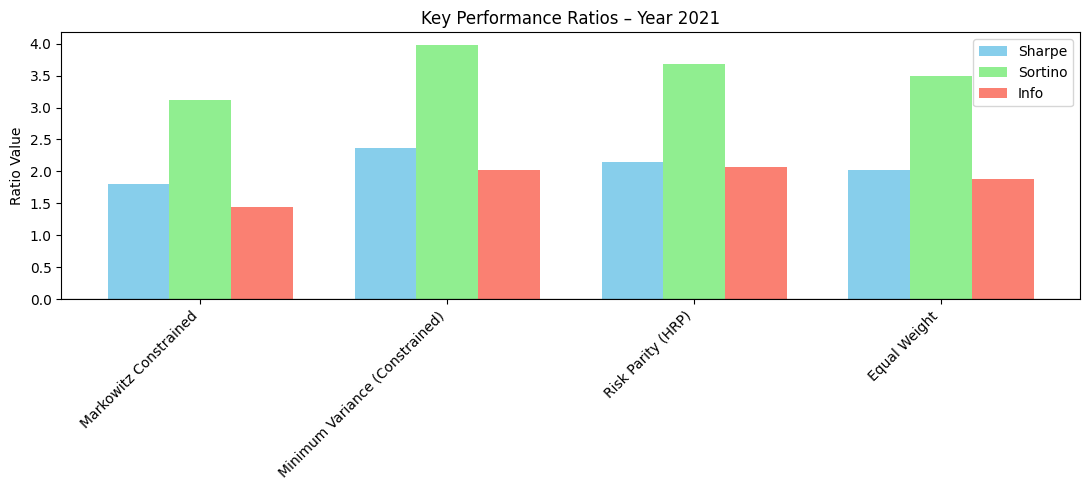

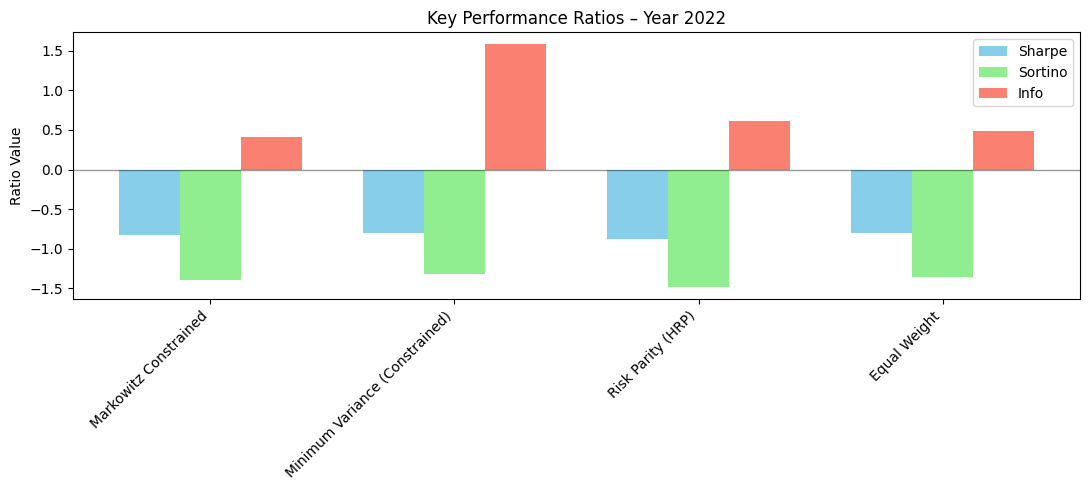

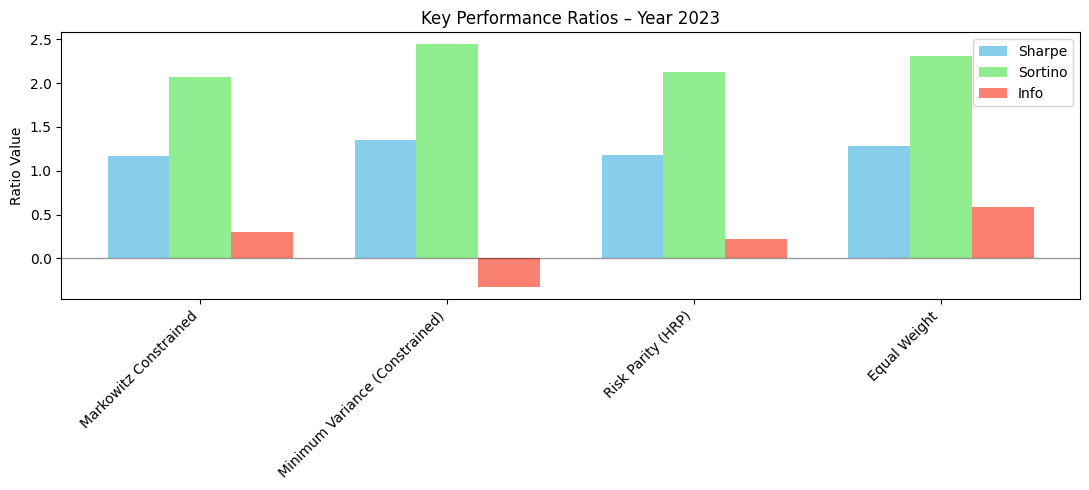

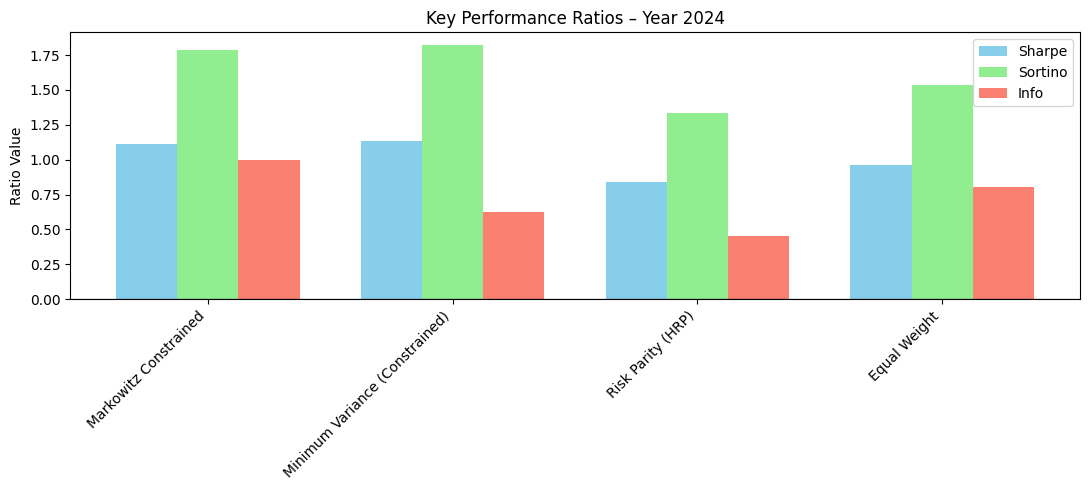

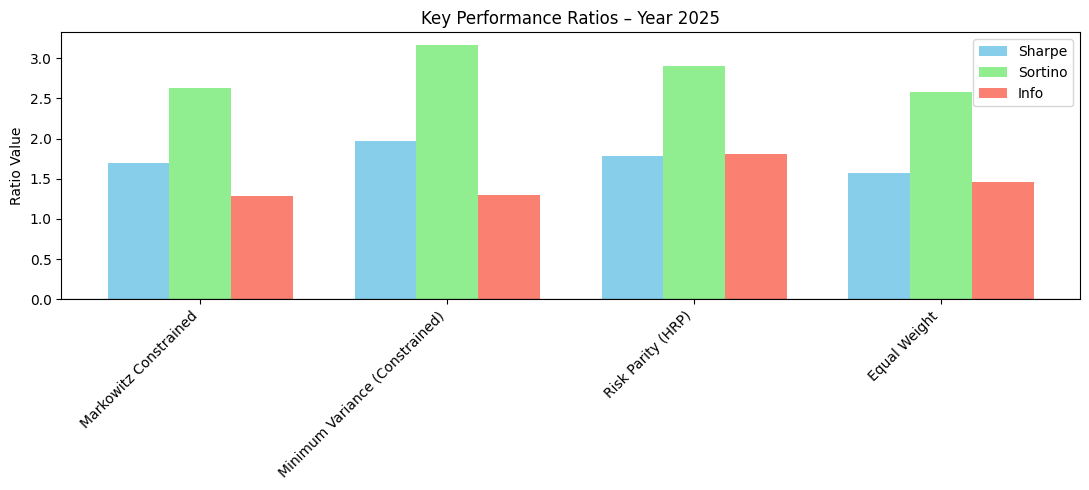

In [12]:
# ==================================================
# Year-by-Year Ratios Comparison
# ==================================================

years = sorted(set(portfolios_oos_daily["equal_weighted"].index.year))
for year in years:
    rows = []
    for name in ordered_models:
        s = portfolios_oos_daily[name]
        b = benchmark_return_series
        s_year = s[s.index.year == year]
        b_year = b[b.index.year == year]
        common = s_year.index.intersection(b_year.index)
        if len(common) < 10:
            continue
        s_year, b_year = s_year.loc[common], b_year.loc[common]
        rows.append({
            "Sharpe (Ann.)":  port_metrics_sharpe_ratio(s_year, risk_free_rate_annual, trading_days_per_year),
            "Sortino (Ann.)": port_metrics_sortino_ratio(s_year, risk_free_rate_annual, trading_days_per_year),
            "Info (Ann.)":    port_metrics_information_ratio(s_year, b_year, trading_days_per_year),
        })
    if not rows:
        continue
    df = pd.DataFrame(rows, index=[pretty_names[m] for m in ordered_models if m in portfolios_oos_daily])
    plt.figure(figsize=(11,5))
    bar_width = 0.25
    x = np.arange(len(df.index))
    plt.bar(x - bar_width, df["Sharpe (Ann.)"],  width=bar_width, label="Sharpe",  color="skyblue")
    plt.bar(x,             df["Sortino (Ann.)"], width=bar_width, label="Sortino", color="lightgreen")
    plt.bar(x + bar_width, df["Info (Ann.)"],    width=bar_width, label="Info",    color="salmon")
    plt.axhline(0, color="black", lw=1, alpha=0.4)
    plt.title(f"Key Performance Ratios – Year {year}")
    plt.ylabel("Ratio Value")
    plt.xticks(x, df.index, rotation=45, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.show()

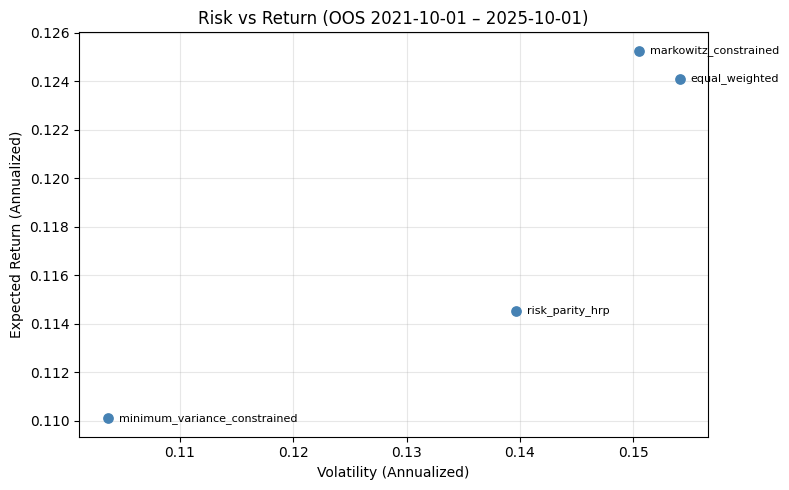

In [ ]:
# ==================================================
# Risk–Return Scatter (OOS)
# ==================================================

plt.figure(figsize=(8, 5))

x = metrics_table_oos["Vol (Ann.)"]
y = metrics_table_oos["Return (Ann.)"]

plt.scatter(x, y, color="steelblue", s=45, zorder=3)

# Label points directly (no arrows or jitter)
for i, txt in enumerate(metrics_table_oos.index):
    plt.text(
        x.iloc[i] + 0.001,   # small horizontal offset for readability
        y.iloc[i],
        txt,
        fontsize=8,
        ha="left",
        va="center"
    )

plt.title(f"Risk vs Return (OOS {start_lbl} – {end_lbl})", fontsize=12)
plt.xlabel("Volatility (Annualized)", fontsize=10)
plt.ylabel("Expected Return (Annualized)", fontsize=10)
plt.grid(True, alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

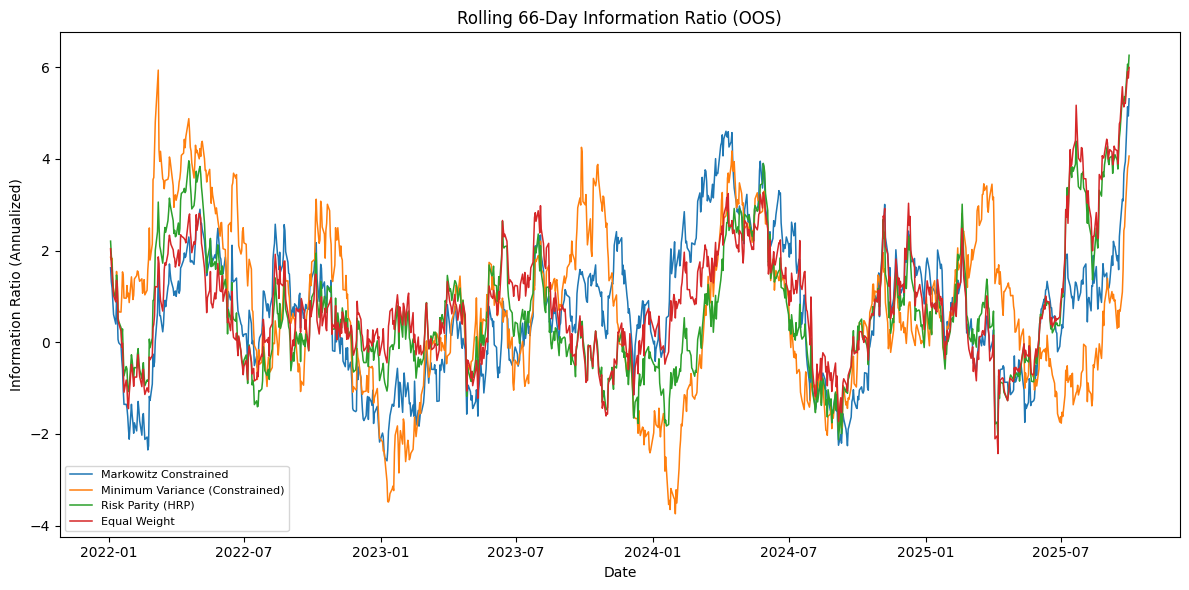

In [14]:
# ==================================================
# Rolling Information Ratio (OOS, ≈ Quarterly)
# ==================================================

window_days = 66  # ≈ quarterly
plt.figure(figsize=(12, 6))

for m in ordered_models:
    s = portfolios_oos_daily[m]
    if s.empty:
        continue

    # --- Align with benchmark ---
    common = s.index.intersection(benchmark_return_series.index)
    diff = s.loc[common] - benchmark_return_series.loc[common]

    # --- Rolling mean & std of active returns ---
    roll_mean_diff = diff.rolling(window_days).mean()
    roll_std_diff  = diff.rolling(window_days).std()

    # --- Rolling Information Ratio (annualized) ---
    roll_info = (roll_mean_diff / roll_std_diff) * np.sqrt(trading_days_per_year)

    plt.plot(roll_info, lw=1.1, label=pretty_names[m])

plt.title(f"Rolling {window_days}-Day Information Ratio (OOS)", fontsize=12)

plt.ylabel("Information Ratio (Annualized)", fontsize=10)
plt.xlabel("Date", fontsize=10)
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

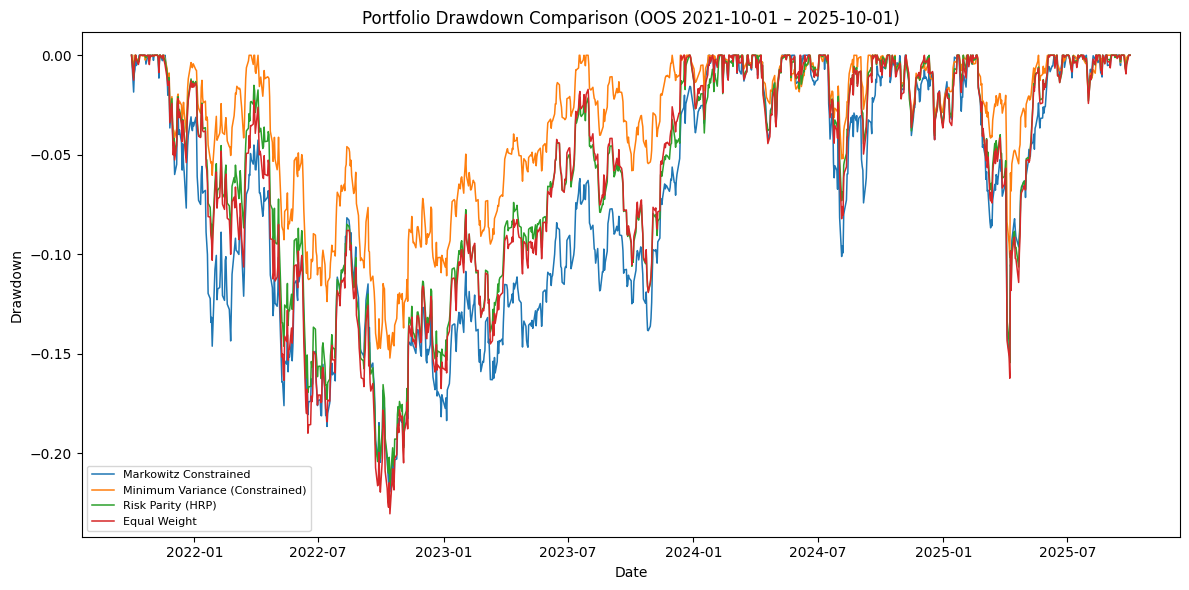

In [15]:
# ==================================================
# Portfolio Drawdowns (OOS)
# ==================================================

plt.figure(figsize=(12, 6))
for name in ordered_models:
    s = portfolios_oos_daily[name]
    if s.empty:
        continue
    cum_returns = (1 + s).cumprod()
    drawdowns = cum_returns / cum_returns.cummax() - 1
    plt.plot(drawdowns, lw=1.1, label=pretty_names[name])

plt.title(f"Portfolio Drawdown Comparison (OOS {start_lbl} – {end_lbl})", fontsize=12)

plt.ylabel("Drawdown", fontsize=10)
plt.xlabel("Date", fontsize=10)
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

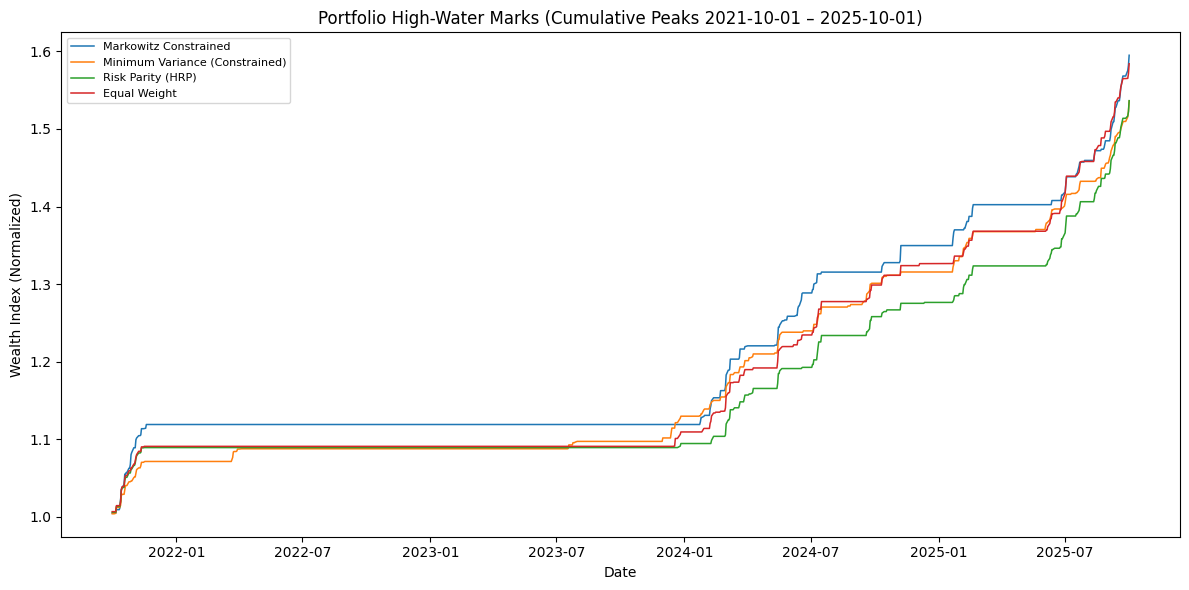

In [ ]:
# ==================================================
# Portfolio High-Water Marks (OOS)
# ==================================================

plt.figure(figsize=(12, 6))
for name in ordered_models:
    s = portfolios_oos_daily[name]
    if s.empty:
        continue
    cum_returns = (1 + s).cumprod()
    hwm_series = cum_returns.cummax()
    plt.plot(hwm_series, lw=1.1, label=pretty_names[name])

plt.title(f"Portfolio High-Water Marks (Cumulative Peaks {start_lbl} – {end_lbl})", fontsize=12)

plt.ylabel("Wealth Index (Normalized)", fontsize=10)
plt.xlabel("Date", fontsize=10)
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()


=== GARCH(1,1) Conditional Volatility (OOS Period) ===
[INFO] GARCH(1,1) fitted for markowitz_constrained (obs: 1033)
[INFO] GARCH(1,1) fitted for minimum_variance_constrained (obs: 1033)
[INFO] GARCH(1,1) fitted for risk_parity_hrp (obs: 1033)
[INFO] GARCH(1,1) fitted for equal_weighted (obs: 1033)


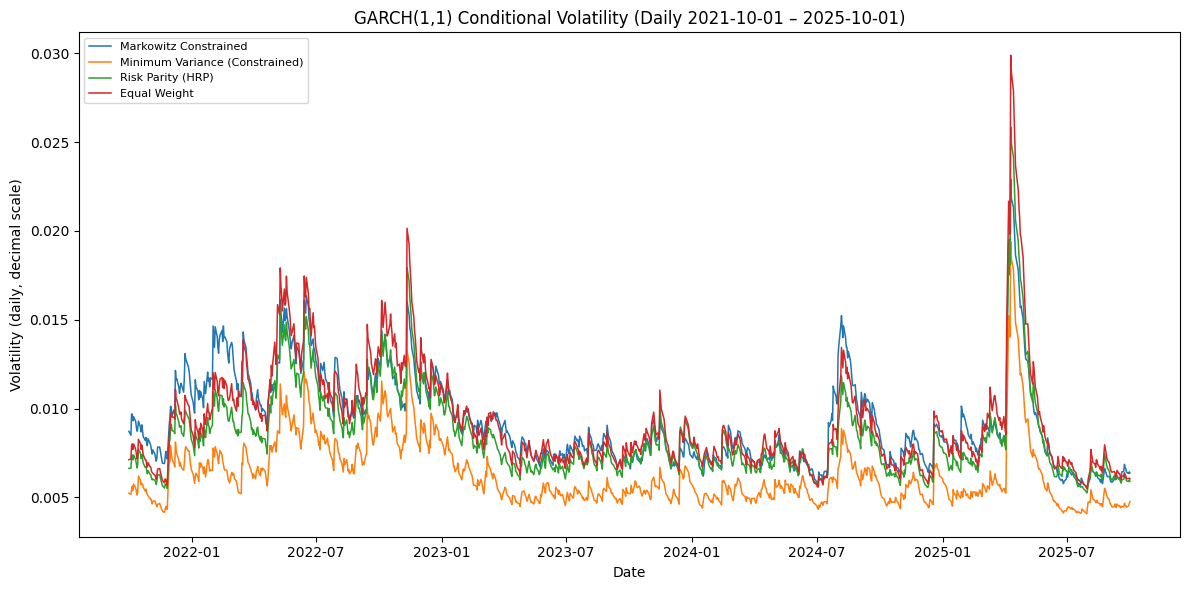

In [17]:
# ==================================================
# Conditional Volatility via GARCH(1,1)
# ==================================================

print("\n" + "="*90)
print("=== GARCH(1,1) Conditional Volatility (OOS Period) ===")
print("="*90)

# Prepare OOS data only
returns_oos = {m: s.loc["2021-10-01":] for m, s in portfolios_oos_daily.items() if not s.empty}

# Fit and collect conditional volatility series
garch_vols = {}

for name, series in returns_oos.items():
    try:
        # remove NaNs and ensure mean-centered
        r = series.dropna() * 100  # scale to % for numerical stability
        model = arch_model(r, vol='Garch', p=1, q=1, mean='Zero')
        res = model.fit(disp="off")
        cond_vol = res.conditional_volatility / 100  # back to decimal scale
        garch_vols[name] = cond_vol
        print(f"[INFO] GARCH(1,1) fitted for {name} (obs: {len(r)})")
    except Exception as e:
        print(f"[WARN] {name}: GARCH fitting failed ({e})")

# --- Plot all conditional volatilities ---
plt.figure(figsize=(12,6))
for name, v in garch_vols.items():
    plt.plot(v.index, v, lw=1.1, label=pretty_names.get(name, name))

plt.title(f"GARCH(1,1) Conditional Volatility (Daily {start_lbl} – {end_lbl})", fontsize=12)

plt.ylabel("Volatility (daily, decimal scale)")
plt.xlabel("Date")
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()